# Display Pickle Data

In [1]:
%load_ext autoreload
%autoreload 2

In [12]:
import numpy as np
from matplotlib import pyplot as plt 
import datetime
import time
from pprint import pprint
# from the_collector import Collector
from pickle_save import pickle_write, pickle_read
from collections import namedtuple

vec_t = namedtuple("vec_t","x y z")
imu_t = namedtuple("imu_t","a g m temperature timestamp")

In [6]:
data = {
    "data": list(range(10)),
}
info = {
    "type": "me"
}

pickle_write("test.pkl", data, info)
d = pickle_read("test.pkl")
pprint(d)

Wrote data to test.pkl
Read test.pkl with keys dict_keys(['data', 'info'])
{'data': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'info': {'type': 'me'}}


In [18]:
d = pickle_read("magcal.pkl")
print(d["info"])
print(d["data"][-1])

Read magcal.pkl with keys dict_keys(['data', 'info'])
{'lsm6dsox': {'accel_range_g': 4, 'gyro_range_dps': 2000, 'rate_hz': 208}, 'lis3mdl': {'mag_range_gauss': 4, 'rate_hz': 300}, 'date': '2025-04-06T16:14:06.830062'}
imu_t(a=vec_t(x=0.067138671875, y=-0.065673828125, z=1.0155029296875), g=vec_t(x=0.1220703125, y=-1.28173828125, z=-0.30517578125), m=vec_t(x=-0.6284196376800537, y=0.5307009816169739, z=-0.5687224268913269), temperature=25.83203125, timestamp=2666391775)


In [15]:
accels = [x.a for x in d["data"]]
ts = [x.timestamp for x in d["data"]]

In [16]:
def plot(ts, data, title, subplot=False):
    # w = None
    # if len(data[0] == 4): w = [d.w for d in data]
    x = [d.x for d in data]
    y = [d.y for d in data]
    z = [d.z for d in data]
    if subplot: plt.subplot(311)
    plt.plot(ts, x, label='x')
    plt.grid(True)
    plt.title(title)
    if subplot: plt.subplot(312)
    plt.plot(ts, y, label='y')
    plt.grid(True)
    if subplot: plt.subplot(313)
    plt.plot(ts, z, label='z')
    plt.grid(True)
    if subplot == False: plt.legend()

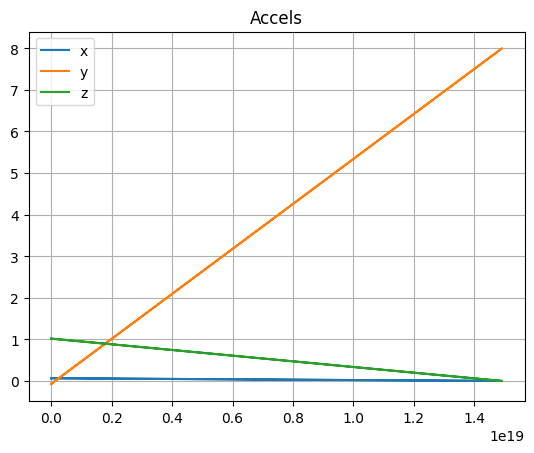

In [17]:
plot(ts, accels, "Accels",False)

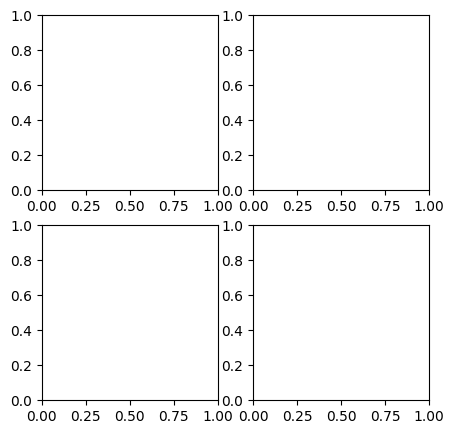

In [20]:
fig, m = plt.subplots(2, 2, figsize=(5, 5))

In [23]:
m[0].scatter(range(10),range(10))

AttributeError: 'numpy.ndarray' object has no attribute 'scatter'

In [24]:
m[0]

array([<Axes: >, <Axes: >], dtype=object)

In [25]:
m

array([[<Axes: >, <Axes: >],
       [<Axes: >, <Axes: >]], dtype=object)

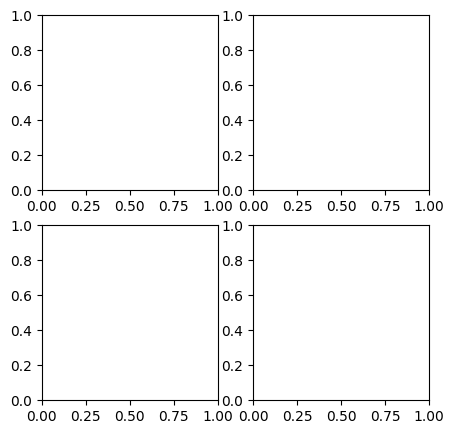

In [26]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(5, 5))